# Inflation — ARMA with makystats

**Series.** Quarterly inflation rate `Dp` (price growth) from the bundled interest–inflation sample, 1972Q2–1998Q4.

**Goal.** Fit a simple AR model with `makystats.arma`, read the coefficients, check residuals, then compare orders with `select_arma_order`.

**Why this series?** Inflation rates are persistent and, at quarterly frequency, often show a **lag-4** seasonal echo. An AR(4) is a transparent baseline before adding MA or formal seasonal ARMA terms.

**Requirements.** `makystats >= 0.1.3`, `pandas`, `numpy`, `matplotlib`.


## 1. Setup


In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from makystats import arma, select_arma_order

plt.style.use("seaborn-v0_8-whitegrid")
plt.rcParams["figure.figsize"] = (11, 4.5)
plt.rcParams["axes.titlesize"] = 12


## 2. Load and inspect the series

Columns: `year`, `quarter`, `Dp` (inflation), `R` (interest rate). We model **`Dp` only**.


In [2]:
raw = pd.read_csv("data/interest_inflation.csv")
raw.index = pd.PeriodIndex.from_fields(
    year=raw["year"].astype(int),
    quarter=raw["quarter"].astype(int),
    freq="Q",
)
y = raw["Dp"].astype(float)
y.name = "inflation"

print(y.index[0], "→", y.index[-1], f"({len(y)} obs.)")
y.describe().round(4)


1972Q2 → 1998Q4 (107 obs.)


count    107.0000
mean       0.0084
std        0.0189
min       -0.0292
25%       -0.0043
50%        0.0087
75%        0.0239
max        0.0430
Name: inflation, dtype: float64

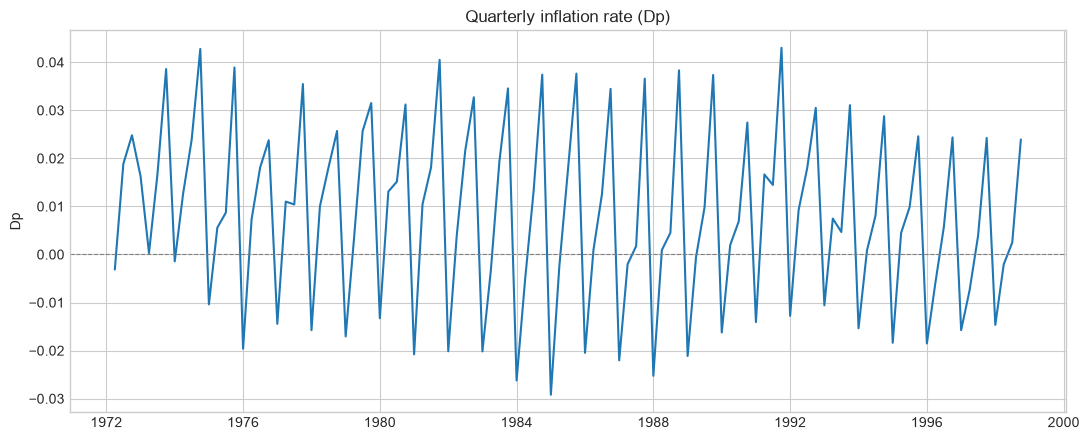

In [3]:
fig, ax = plt.subplots()
ax.plot(y.to_timestamp(), color="C0", lw=1.5)
ax.axhline(0.0, color="0.5", lw=0.8, ls="--")
ax.set_title("Quarterly inflation rate (Dp)")
ax.set_ylabel("Dp")
fig.tight_layout()
plt.show()


### Reading the plot

- Mean inflation is positive over the sample, with large swings in the 1970s.
- No need for a log transform: `Dp` is already a growth rate.
- Quarterly data often need lag **4** (same quarter last year), not only lag 1.


## 3. Model specification

Baseline:

\[
\text{AR}(4)\quad\text{with constant}
\]

| Choice | Reason |
|--------|--------|
| `d = 0` | `Dp` is already differenced prices (inflation rate) |
| `ar = 4` | captures annual seasonal dependence at quarterly frequency |
| `trend = "c"` | non-zero mean inflation |

```python
arma(y, mean="AR", ar=4, d=0, trend="c")
```


## 4. Estimation


In [6]:
res = arma(y, mean="AR", ar=4, d=0, trend="c").fit(verbose=False)
print(res.summary())

                                 ARMA Results                                 
Dep. Variable:               inflation   No. Observations:              103
Model:                       ARMA(4,0)   Log Likelihood:            374.880
Date:                 Tue, 27 Oct 2026   AIC:                      -737.761
Time:                         12:00:48   BIC:                      -721.953
Sample:                         1972Q2   HQIC:                     -731.358
                              - 1998Q4                                     
Covariance Type:                   opg                                     
                      coef   std err         z     P>|z|    [0.025    0.975]
------------------------------------------------------------------------------
const               0.0069    0.0029    2.3731     0.018    0.0012    0.0126
ar.L1              -0.0716    0.0476   -1.5061     0.132   -0.1648    0.0216
ar.L2              -0.0639    0.0520   -1.2274     0.220   -0.1659    0.0381
ar

### Coefficient interpretation

- **const:** mean inflation on the estimation scale (significant if average `Dp` is away from zero).
- **AR(1)–AR(3):** short-run dynamics; often smaller than AR(4) on this sample.
- **AR(4):** usually large and significant → same-quarter-last-year effect.
- **σ²:** innovation variance of the inflation equation.


## 5. Residuals and diagnostics


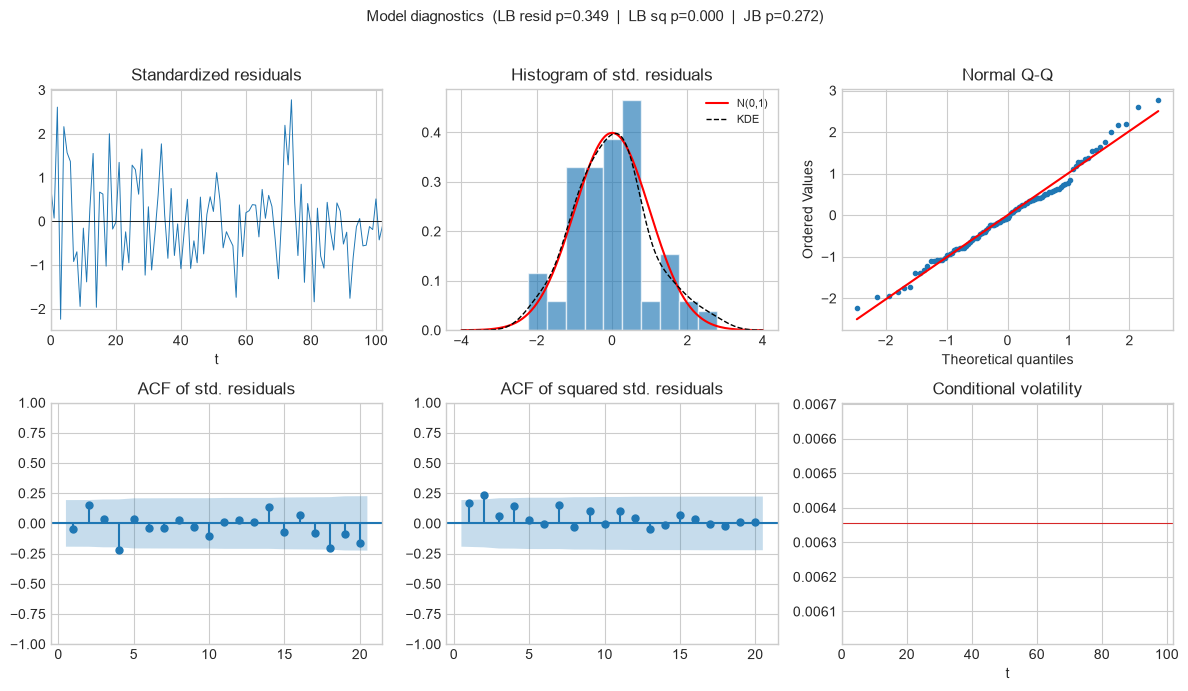

In [7]:
fig = res.plot_diagnostics()
plt.show()


### What to look for

- Residual path around zero after the AR lags fill.
- ACF: remaining spikes at lag 4 would push toward seasonal MA or extra lags.
- Squared residual ACF: strong patterns → consider `arma_garch` for volatility.


In [8]:
lb = res.test_serial_correlation(lags=8)
print(lb)


    lb_stat  lb_pvalue
1  0.104647   0.746322
2  2.266932   0.132161
3  2.691462   0.100887
4  6.007171   0.014248
5  6.278811   0.012219
6  6.375166   0.041272
7  7.191491   0.066038
8  7.378914   0.117169


## 6. Fitted values

With `d = 0`, fitted values are already on the **inflation** scale (no level reconstruction needed).


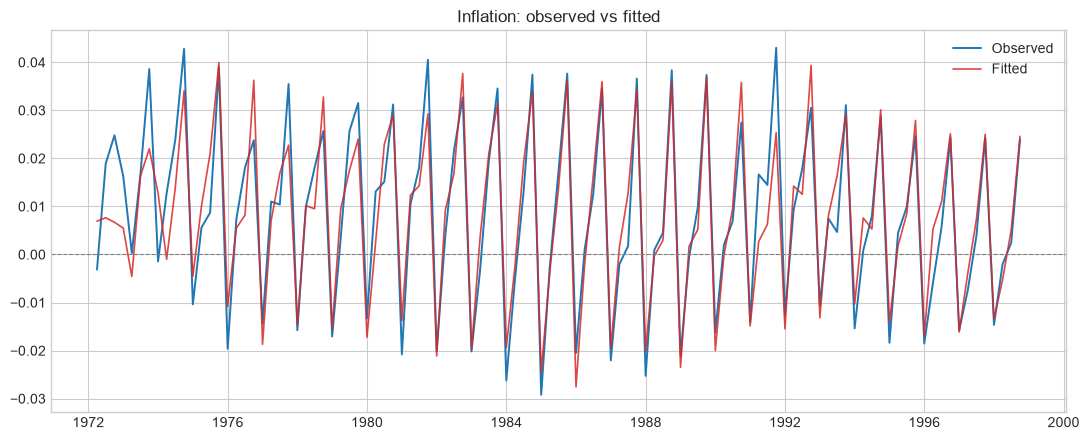

In [9]:
fitted = res.fitted_values_level() if callable(getattr(res, "fitted_values_level", None)) else res.fitted_values

fig, ax = plt.subplots()
ax.plot(y.to_timestamp(), label="Observed", color="C0", lw=1.4)
ax.plot(pd.Series(fitted, index=y.index).to_timestamp(), label="Fitted", color="C3", lw=1.2, alpha=0.85)
ax.axhline(0.0, color="0.5", lw=0.8, ls="--")
ax.set_title("Inflation: observed vs fitted")
ax.legend()
fig.tight_layout()
plt.show()


## 7. Order selection

Grid over non-seasonal \(p\) and \(q\) (no seasonal block). BIC favours parsimony on a short quarterly sample.


In [10]:
table, best = select_arma_order(
    y,
    p_range=range(0, 5),
    q_range=range(0, 3),
    d=0,
    criterion="bic",
    return_best=True,
    verbose=False,
)
table.head(8)


,p,q,dist,mean,in_mean,loglik,aic,bic,hqic,n_params,degenerate,ok,error
"ARMA(4,0)-normal",4,0,normal,AR,None,374.880476,-737.760952,-721.952578,-731.358019,6,False,True,None
"ARMA(4,2)-normal",4,2,normal,AR,None,378.401079,-740.802158,-719.724327,-732.264915,8,False,True,None
"ARMA(4,1)-normal",4,1,normal,AR,None,374.966777,-735.933554,-717.490451,-728.463466,7,False,True,None
"ARMA(3,2)-normal",3,2,normal,AR,None,343.369604,-672.739207,-654.296104,-665.269119,7,False,True,None
"ARMA(3,1)-normal",3,1,normal,AR,None,331.276233,-650.552465,-634.744091,-644.149533,6,False,True,None
"ARMA(2,2)-normal",2,2,normal,AR,None,319.727801,-627.455601,-611.647227,-621.052668,6,False,True,None
"ARMA(3,0)-normal",3,0,normal,AR,None,294.788728,-579.577455,-566.403810,-574.241678,5,False,True,None
"ARMA(2,1)-normal",2,1,normal,AR,None,278.057420,-546.114840,-532.941196,-540.779063,5,False,True,None


In [11]:
print("Best by BIC:", table.index[0])
print(best.summary())

Best by BIC: ARMA(4,0)-normal
                                 ARMA Results                                 
Dep. Variable:               inflation   No. Observations:              103
Model:                       ARMA(4,0)   Log Likelihood:            374.880
Date:                 Tue, 27 Oct 2026   AIC:                      -737.761
Time:                         12:04:03   BIC:                      -721.953
Sample:                         1972Q2   HQIC:                     -731.358
                              - 1998Q4                                     
Covariance Type:                   opg                                     
                      coef   std err         z     P>|z|    [0.025    0.975]
------------------------------------------------------------------------------
const               0.0069    0.0029    2.3731     0.018    0.0012    0.0126
ar.L1              -0.0716    0.0476   -1.5061     0.132   -0.1648    0.0216
ar.L2              -0.0639    0.0520   -1.2274   

### How to read the table

- All candidates share `d = 0` → AIC/BIC are comparable.
- Models with **p ≥ 4** often rank well because of the annual lag.
- If a low-order SARIMA with `seasonal_order=(1,0,1,4)` is preferred later, that is an alternative way to write the same seasonal dependence.


## 8. Short forecast


            mean     lower     upper     sigma
1999Q1 -0.012694 -0.025149 -0.000239  0.006355
1999Q2 -0.000486 -0.012941  0.011969  0.006355
1999Q3  0.003697 -0.008758  0.016152  0.006355
1999Q4  0.023985  0.011530  0.036440  0.006355
2000Q1 -0.011131 -0.023586  0.001324  0.006355


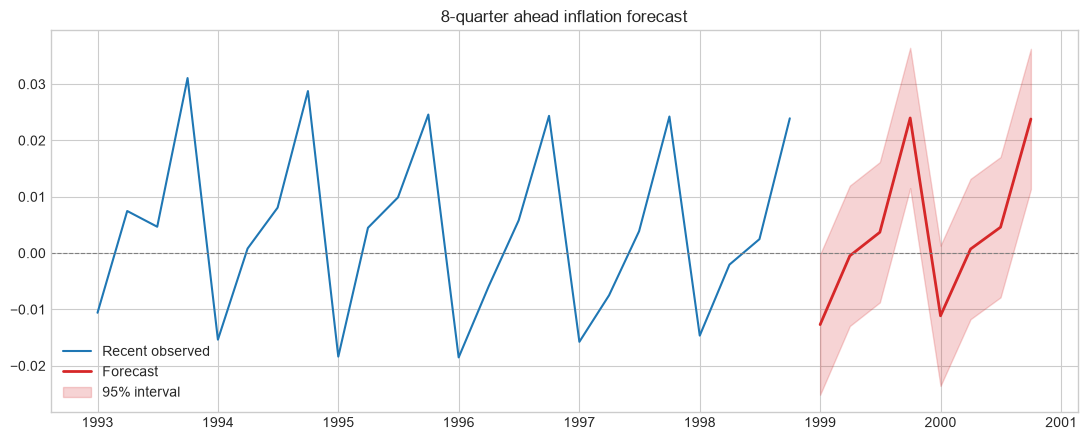

In [12]:
fc = res.forecast(steps=8, conf_int=True)
print(fc.head())

fig, ax = plt.subplots()
ax.plot(y.to_timestamp().iloc[-24:], label="Recent observed", color="C0")
ax.plot(fc["mean"].to_timestamp() if hasattr(fc["mean"], "to_timestamp") else fc["mean"],
        label="Forecast", color="C3", lw=2)
if "lower" in fc.columns:
    ax.fill_between(
        fc.index.to_timestamp() if hasattr(fc.index, "to_timestamp") else fc.index,
        fc["lower"],
        fc["upper"],
        color="C3",
        alpha=0.2,
        label="95% interval",
    )
ax.axhline(0.0, color="0.5", lw=0.8, ls="--")
ax.set_title("8-quarter ahead inflation forecast")
ax.legend()
fig.tight_layout()
plt.show()


## 9. Takeaways

1. **Inflation rates** are a natural ARMA target: already in growth form, economic reading of persistence.
2. At **quarterly** frequency, lag **4** (or seasonal ARMA with `s=4`) is often essential.
3. **makystats** keeps Period/Datetime indexes on fits and forecasts and exposes `test_serial_correlation`.
4. For volatility of inflation shocks, move the same mean equation into `arma_garch`.
